
# Continuous Stability–Localization Relationship Analysis

## 1. Research Objective

This notebook extends the stability–localization disagreement audit by examining the continuous relationship between explanation similarity and localization alignment change.

The original audit identified disagreement using two thresholds:

- Explanation similarity ≥ 0.80
- Localization alignment change ≤ −0.05

Although these thresholds identify cases where explanations remain stable while localization alignment deteriorates, they do not fully characterize the relationship between the two measurements.

This analysis investigates:

1. Whether explanation similarity is associated with localization alignment change.
2. Whether this relationship differs across Integrated Gradients, Score-CAM, and Occlusion Sensitivity.
3. Whether substantial localization losses occur among highly stable explanations.

The analysis uses previously computed evaluation results. No model retraining or additional attribution generation is required.


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_DIR = Path("/content/drive/MyDrive/XAI_project_Expo_1_folder")

DATA_PATH = (
    PROJECT_DIR
    / "Results"
    / "ExpandedEvaluation"
    / "stability_localization_area_enriched.csv"
)

assert DATA_PATH.exists(), f"CSV not found: {DATA_PATH}"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (2700, 24)


,sop_uid,true_class,original_predicted_class,original_correct,corrupted_predicted_class,prediction_changed,corruption,severity,sigma,opacity_probability,...,method,original_alignment,alignment_change,high_stability,localization_loss,disagreement,box_area_fraction,attribution_enrichment,original_enrichment,enrichment_change
0,1.2.276.0.7230010.3.1.4.8323329.10261.15178743...,1,1,1,1,0,Blur,mild,0.50,0.545375,...,Integrated Gradients,0.124,-0.009625,True,False,False,0.041162,2.778629,3.012471,-0.233843
1,1.2.276.0.7230010.3.1.4.8323329.10261.15178743...,1,1,1,1,0,Blur,moderate,1.50,0.535043,...,Integrated Gradients,0.124,-0.020098,False,False,False,0.041162,2.524204,3.012471,-0.488267
2,1.2.276.0.7230010.3.1.4.8323329.10261.15178743...,1,1,1,1,0,Blur,severe,3.00,0.569804,...,Integrated Gradients,0.124,0.013435,False,False,False,0.041162,3.338858,3.012471,0.326387
3,1.2.276.0.7230010.3.1.4.8323329.10261.15178743...,1,1,1,1,0,Noise,mild,0.02,0.545769,...,Integrated Gradients,0.124,0.021971,False,False,False,0.041162,3.546250,3.012471,0.533779
4,1.2.276.0.7230010.3.1.4.8323329.10261.15178743...,1,1,1,1,0,Noise,moderate,0.05,0.554825,...,Integrated Gradients,0.124,-0.066344,False,True,False,0.041162,1.400690,3.012471,-1.611782


In [ ]:
required_columns = [
    "sop_uid",
    "method",
    "corruption",
    "severity",
    "explanation_similarity",
    "alignment_change",
]

missing_columns = [col for col in required_columns if col not in df.columns]

assert not missing_columns, f"Missing columns: {missing_columns}"

print("Unique images:", df["sop_uid"].nunique())
print("Methods:", df["method"].unique())
print("Corruptions:", df["corruption"].unique())
print("Severities:", df["severity"].unique())

print("\nMissing values:")
print(df[required_columns].isna().sum())

print("\nSummary statistics:")
display(df[["explanation_similarity", "alignment_change"]].describe())

Unique images: 150
Methods: ['Integrated Gradients' 'Occlusion Sensitivity' 'Score-CAM']
Corruptions: ['Blur' 'Noise']
Severities: ['mild' 'moderate' 'severe']

Missing values:
sop_uid                   0
method                    0
corruption                0
severity                  0
explanation_similarity    0
alignment_change          0
dtype: int64

Summary statistics:


,explanation_similarity,alignment_change
count,2700.000000,2700.000000
mean,0.677433,-0.068880
std,0.243605,0.106666
min,-0.256267,-0.533850
25%,0.527854,-0.111515
50%,0.711712,-0.030316
75%,0.874463,0.000832
max,0.999285,0.194102



## 2. Continuous Relationship Between Explanation Stability and Localization Change

The original disagreement audit used predefined thresholds to identify cases where explanations remained stable despite decreasing localization alignment.

This section examines the relationship between explanation similarity and localization alignment change as continuous measurements.

We use Spearman rank correlation to assess whether higher explanation similarity is associated with greater preservation of localization alignment.

We also visualize the relationship separately for Integrated Gradients, Occlusion Sensitivity, and Score-CAM.

Because each image contributes multiple observations across methods and corruption conditions, the correlations in this section are descriptive. Uncertainty accounting for repeated images will be examined separately.


In [ ]:
from scipy.stats import spearmanr

# Overall descriptive correlation
rho, p_value = spearmanr(df["explanation_similarity"], df["alignment_change"])

print("Overall Spearman correlation")
print(f"rho = {rho:.4f}")
print(f"Naive p-value = {p_value:.4g}")

# Correlations for each XAI method
results = []

for method, group in df.groupby("method"):
    method_rho, method_p = spearmanr(
        group["explanation_similarity"], group["alignment_change"]
    )

    results.append(
        {
            "method": method,
            "n_evaluations": len(group),
            "spearman_rho": method_rho,
            "naive_p_value": method_p,
        }
    )

correlation_df = pd.DataFrame(results)

display(correlation_df)

Overall Spearman correlation
rho = 0.5075
Naive p-value = 1.067e-176


,method,n_evaluations,spearman_rho,naive_p_value
0,Integrated Gradients,900,0.503965,3.856785e-59
1,Occlusion Sensitivity,900,0.336456,2.936004e-25
2,Score-CAM,900,0.621042,4.132730e-97


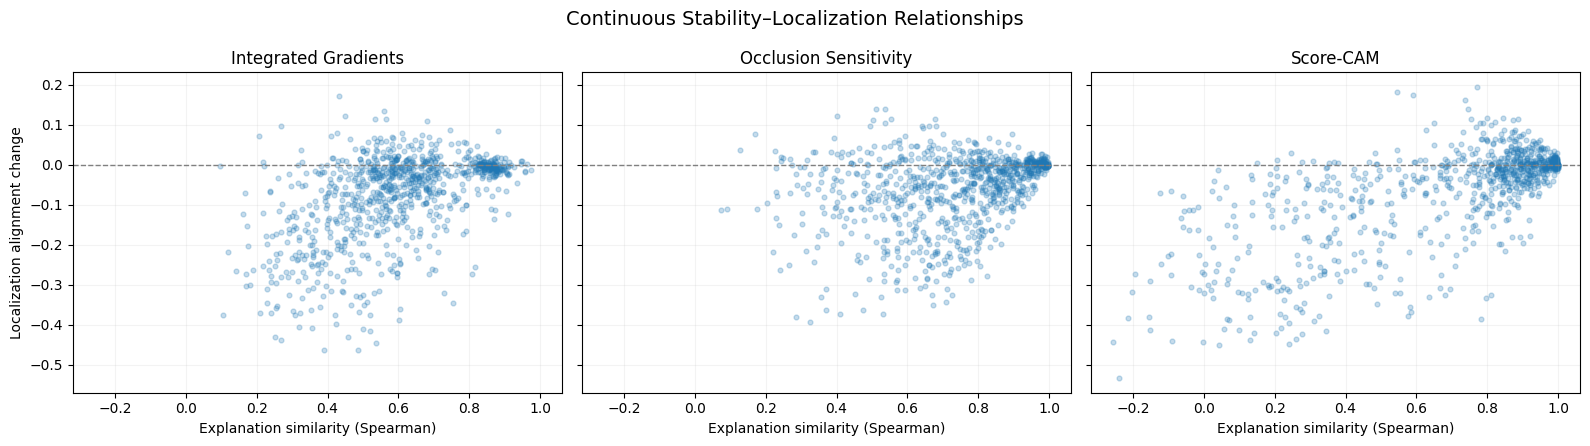

In [ ]:
import matplotlib.pyplot as plt

methods = ["Integrated Gradients", "Occlusion Sensitivity", "Score-CAM"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)

for ax, method in zip(axes, methods):
    subset = df[df["method"] == method]

    ax.scatter(
        subset["explanation_similarity"], subset["alignment_change"], alpha=0.25, s=12
    )

    ax.axhline(0, color="gray", linestyle="--", linewidth=1)

    ax.set_title(method)
    ax.set_xlabel("Explanation similarity (Spearman)")
    ax.grid(alpha=0.15)

axes[0].set_ylabel("Localization alignment change")

fig.suptitle("Continuous Stability–Localization Relationships", fontsize=14)

plt.tight_layout()
plt.show()


## 3. Image-Cluster Bootstrap Uncertainty

The continuous analysis suggests a positive association between explanation similarity and localization alignment change.

However, each chest X-ray contributes repeated observations across three XAI methods and six corruption conditions. Treating all 2,700 evaluations as independent would underestimate uncertainty.

To account for this structure, we use an image-cluster bootstrap:

1. Sample chest X-ray identifiers with replacement.
2. Retain all method–corruption evaluations associated with each sampled image.
3. Recalculate the Spearman correlation for each bootstrap sample.
4. Use the resulting distribution to estimate 95% confidence intervals.

We calculate confidence intervals for the overall correlation and separately for each XAI method.

These intervals quantify sampling uncertainty across images in the evaluated dataset. They do not establish clinical generalizability or account for uncertainty from retraining the model.


In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

rng = np.random.default_rng(42)
n_bootstrap = 2000

methods = ["Integrated Gradients", "Occlusion Sensitivity", "Score-CAM"]

# Group all evaluations by image identifier
image_groups = {uid: group for uid, group in df.groupby("sop_uid")}

image_ids = np.array(list(image_groups.keys()))
n_images = len(image_ids)

bootstrap_results = {"Overall": [], **{method: [] for method in methods}}

for _ in range(n_bootstrap):

    sampled_ids = rng.choice(image_ids, size=n_images, replace=True)

    sampled_df = pd.concat(
        [image_groups[uid] for uid in sampled_ids], ignore_index=True
    )

    # Overall correlation
    overall_rho = spearmanr(
        sampled_df["explanation_similarity"], sampled_df["alignment_change"]
    ).statistic

    bootstrap_results["Overall"].append(overall_rho)

    # Method-specific correlations
    for method in methods:
        subset = sampled_df[sampled_df["method"] == method]

        rho = spearmanr(
            subset["explanation_similarity"], subset["alignment_change"]
        ).statistic

        bootstrap_results[method].append(rho)

# Summarize bootstrap confidence intervals
summary = []

for label, values in bootstrap_results.items():

    values = np.asarray(values)

    lower, upper = np.percentile(values, [2.5, 97.5])

    summary.append(
        {
            "method": label,
            "bootstrap_mean_rho": values.mean(),
            "ci_lower_95": lower,
            "ci_upper_95": upper,
        }
    )

bootstrap_summary = pd.DataFrame(summary)

display(bootstrap_summary)

,method,bootstrap_mean_rho,ci_lower_95,ci_upper_95
0,Overall,0.508282,0.452673,0.559039
1,Integrated Gradients,0.505790,0.432372,0.578420
2,Occlusion Sensitivity,0.337112,0.238875,0.432358
3,Score-CAM,0.621635,0.567984,0.669958



## 4. Localization Change Across Explanation Stability Levels

The continuous correlation analysis found a positive association between explanation similarity and localization alignment change.

However, an overall positive association does not guarantee that highly stable explanations preserve localization alignment in every evaluation.

This section examines the distribution of localization alignment changes across explanation similarity levels.

We summarize the median, interquartile range, and frequency of substantial localization loss within each similarity interval.

These analyses are descriptive and complement the continuous correlations. Similarity intervals are used for interpretation rather than as new definitions of explanation reliability.


In [ ]:
# Define similarity intervals for descriptive analysis
bins = [-np.inf, 0.4, 0.6, 0.8, 0.9, np.inf]

labels = ["< 0.40", "0.40–0.60", "0.60–0.80", "0.80–0.90", "≥ 0.90"]

# Create an in-memory working copy
analysis_df = df.copy()

analysis_df["stability_group"] = pd.cut(
    analysis_df["explanation_similarity"], bins=bins, labels=labels, right=False
)

# Substantial localization loss: at least 5 percentage points
analysis_df["substantial_loss"] = analysis_df["alignment_change"] <= -0.05

stability_summary = (
    analysis_df.groupby("stability_group", observed=True)
    .agg(
        n_evaluations=("alignment_change", "size"),
        median_alignment_change=("alignment_change", "median"),
        q25_alignment_change=("alignment_change", lambda x: x.quantile(0.25)),
        q75_alignment_change=("alignment_change", lambda x: x.quantile(0.75)),
        substantial_loss_rate=("substantial_loss", "mean"),
    )
    .reset_index()
)

stability_summary["substantial_loss_rate"] *= 100

display(stability_summary.round(4))

,stability_group,n_evaluations,median_alignment_change,q25_alignment_change,q75_alignment_change,substantial_loss_rate
0,< 0.40,386,-0.1790,-0.2840,-0.0721,81.3472
1,0.40–0.60,564,-0.0732,-0.1548,-0.0127,59.3972
2,0.60–0.80,674,-0.0464,-0.1170,-0.0030,48.2196
3,0.80–0.90,540,-0.0125,-0.0468,0.0033,24.4444
4,≥ 0.90,536,-0.0012,-0.0124,0.0072,7.2761


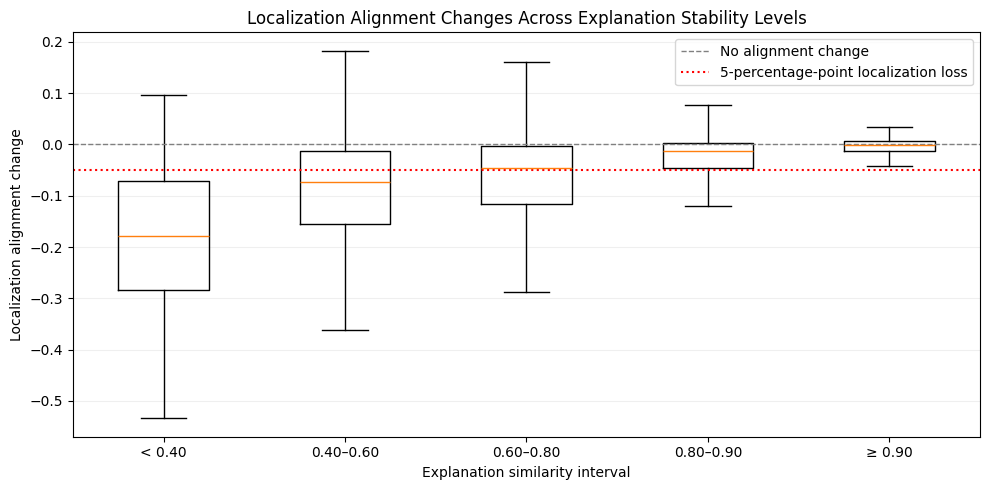

In [ ]:
import matplotlib.pyplot as plt

plot_data = [
    analysis_df.loc[analysis_df["stability_group"] == label, "alignment_change"]
    .dropna()
    .values
    for label in labels
]

fig, ax = plt.subplots(figsize=(10, 5))

ax.boxplot(plot_data, tick_labels=labels, showfliers=False)

ax.axhline(0, color="gray", linestyle="--", linewidth=1, label="No alignment change")

ax.axhline(
    -0.05,
    color="red",
    linestyle=":",
    linewidth=1.5,
    label="5-percentage-point localization loss",
)

ax.set_xlabel("Explanation similarity interval")
ax.set_ylabel("Localization alignment change")
ax.set_title("Localization Alignment Changes Across Explanation Stability Levels")

ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


## 5. High-Stability Localization Loss by XAI Method

The preceding analysis found that 39 of 536 evaluations with explanation similarity ≥ 0.90 experienced a localization alignment decrease of at least five percentage points.

This section examines how those cases are distributed across Integrated Gradients, Occlusion Sensitivity, and Score-CAM.

We calculate the frequency of substantial localization loss within the very-high-stability subset for each method.

The objective is to characterize method-specific exceptions to the overall positive stability–localization relationship, rather than establish which XAI method is universally more reliable.


In [ ]:
high_stability = analysis_df[analysis_df["explanation_similarity"] >= 0.90].copy()

method_loss_summary = (
    high_stability.groupby("method")
    .agg(
        n_high_stability=("substantial_loss", "size"),
        n_substantial_loss=("substantial_loss", "sum"),
        loss_rate=("substantial_loss", "mean"),
    )
    .reset_index()
)

method_loss_summary["loss_rate"] *= 100

display(method_loss_summary.round(3))

print("\nTotal very-high-stability evaluations:", len(high_stability))

print("Total substantial-loss cases:", high_stability["substantial_loss"].sum())

,method,n_high_stability,n_substantial_loss,loss_rate
0,Integrated Gradients,22,2,9.091
1,Occlusion Sensitivity,212,23,10.849
2,Score-CAM,302,14,4.636



Total very-high-stability evaluations: 536
Total substantial-loss cases: 39



## 6. Corruption-Stratified Stability–Localization Analysis

### Objective

The preceding analysis found a positive association between explanation similarity and localization alignment change across all evaluated corruption conditions.

However, the overall association may partly reflect differences between Gaussian blur and Gaussian noise or their severity levels.

To investigate this possibility, we calculate Spearman correlations separately within each corruption type and severity.

We also examine method-specific correlations within each condition.

### Research Question

Does the positive association between explanation stability and localization preservation persist when corruption type and severity are held constant?

### Interpretation

This analysis helps distinguish the pooled association from relationships observed within individual corruption conditions.

Because each image contributes repeated observations across methods and conditions, the initial correlations are descriptive. We do not interpret conventional p-values as independent-observation evidence.


In [ ]:
from scipy.stats import spearmanr
import pandas as pd
import numpy as np

severity_order = ["mild", "moderate", "severe"]
corruption_order = ["Blur", "Noise"]

condition_results = []

for (corruption, severity), group in df.groupby(["corruption", "severity"]):
    rho = spearmanr(
        group["explanation_similarity"], group["alignment_change"]
    ).statistic

    condition_results.append(
        {
            "corruption": corruption,
            "severity": severity,
            "n_evaluations": len(group),
            "n_images": group["sop_uid"].nunique(),
            "spearman_rho": rho,
        }
    )

condition_summary = pd.DataFrame(condition_results)

condition_summary["corruption"] = pd.Categorical(
    condition_summary["corruption"], categories=corruption_order, ordered=True
)

condition_summary["severity"] = pd.Categorical(
    condition_summary["severity"], categories=severity_order, ordered=True
)

condition_summary = condition_summary.sort_values(
    ["corruption", "severity"]
).reset_index(drop=True)

display(condition_summary.round(4))

,corruption,severity,n_evaluations,n_images,spearman_rho
0,Blur,mild,450,150,0.2165
1,Blur,moderate,450,150,0.0461
2,Blur,severe,450,150,0.0124
3,Noise,mild,450,150,0.2226
4,Noise,moderate,450,150,0.1993
5,Noise,severe,450,150,0.1152


In [ ]:
method_condition_results = []

for (method, corruption, severity), group in df.groupby(
    ["method", "corruption", "severity"]
):
    rho = spearmanr(
        group["explanation_similarity"], group["alignment_change"]
    ).statistic

    method_condition_results.append(
        {
            "method": method,
            "corruption": corruption,
            "severity": severity,
            "n_images": group["sop_uid"].nunique(),
            "spearman_rho": rho,
        }
    )

method_condition_df = pd.DataFrame(method_condition_results)

method_condition_df["condition"] = (
    method_condition_df["corruption"] + " - " + method_condition_df["severity"]
)

method_condition_table = method_condition_df.pivot(
    index="method", columns="condition", values="spearman_rho"
)

ordered_conditions = [
    f"{corruption} - {severity}"
    for corruption in corruption_order
    for severity in severity_order
]

method_condition_table = method_condition_table[ordered_conditions]

display(method_condition_table.round(3))

condition,Blur - mild,Blur - moderate,Blur - severe,Noise - mild,Noise - moderate,Noise - severe
method,,,,,,
Integrated Gradients,-0.168,-0.014,0.088,0.158,0.159,-0.038
Occlusion Sensitivity,-0.208,-0.124,-0.067,-0.203,-0.197,-0.222
Score-CAM,-0.180,-0.098,0.068,0.380,0.453,0.403



## 7. Uncertainty in Method- and Corruption-Specific Correlations

The stratified analysis revealed that the relationship between explanation similarity and localization alignment change varies across XAI methods and corruption conditions.

To assess the uncertainty of these descriptive relationships, we estimate 95% bootstrap confidence intervals for each method–corruption combination.

Each combination contains one evaluation per chest X-ray, so we resample image-level observations with replacement.

These intervals help characterize uncertainty within the evaluated dataset. They do not establish causal relationships or generalizability to other models, datasets, or clinical environments.


In [ ]:
from scipy.stats import spearmanr
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
n_bootstrap = 2000

bootstrap_rows = []

for (method, corruption, severity), group in df.groupby(
    ["method", "corruption", "severity"]
):
    x = group["explanation_similarity"].to_numpy()
    y = group["alignment_change"].to_numpy()

    n = len(group)

    observed_rho = spearmanr(x, y).statistic

    bootstrap_rhos = []

    for _ in range(n_bootstrap):
        indices = rng.integers(0, n, size=n)

        rho = spearmanr(x[indices], y[indices]).statistic

        if np.isfinite(rho):
            bootstrap_rhos.append(rho)

    lower, upper = np.percentile(bootstrap_rhos, [2.5, 97.5])

    bootstrap_rows.append(
        {
            "method": method,
            "corruption": corruption,
            "severity": severity,
            "n_images": group["sop_uid"].nunique(),
            "spearman_rho": observed_rho,
            "ci_lower_95": lower,
            "ci_upper_95": upper,
        }
    )

stratified_bootstrap_df = pd.DataFrame(bootstrap_rows)

display(
    stratified_bootstrap_df.sort_values(["method", "corruption", "severity"]).round(3)
)

,method,corruption,severity,n_images,spearman_rho,ci_lower_95,ci_upper_95
0,Integrated Gradients,Blur,mild,150,-0.168,-0.337,0.002
1,Integrated Gradients,Blur,moderate,150,-0.014,-0.185,0.155
2,Integrated Gradients,Blur,severe,150,0.088,-0.086,0.264
3,Integrated Gradients,Noise,mild,150,0.158,0.003,0.316
4,Integrated Gradients,Noise,moderate,150,0.159,-0.002,0.316
5,Integrated Gradients,Noise,severe,150,-0.038,-0.187,0.119
6,Occlusion Sensitivity,Blur,mild,150,-0.208,-0.374,-0.029
7,Occlusion Sensitivity,Blur,moderate,150,-0.124,-0.276,0.051
8,Occlusion Sensitivity,Blur,severe,150,-0.067,-0.214,0.089
9,Occlusion Sensitivity,Noise,mild,150,-0.203,-0.353,-0.042



### Interpretation of Stratified Results

The overall analysis identified a moderate positive association between explanation similarity and localization alignment change (Spearman ρ = 0.508, 95% image-cluster bootstrap CI [0.453, 0.559]).

However, the relationship was substantially weaker when evaluated within individual corruption conditions. The six condition-level correlations ranged from 0.012 to 0.223.

Further stratification by XAI method revealed heterogeneous patterns:

- **Integrated Gradients:** Correlations were generally weak and varied in direction. Most bootstrap confidence intervals included zero.
- **Occlusion Sensitivity:** All six observed correlations were negative. Four bootstrap confidence intervals excluded zero.
- **Score-CAM:** Correlations were negative or weak under blur but positive under Gaussian noise. All three noise-condition confidence intervals excluded zero.

These results suggest that the pooled association does not consistently describe the relationship within individual methods and corruption conditions.

The results also highlight the importance of evaluation granularity. A positive pooled correlation should not automatically be interpreted as evidence that explanation stability reliably predicts localization preservation across all settings.

The 18 method–condition comparisons are exploratory. Their confidence intervals are not adjusted for multiple comparisons, and individual correlations should not be interpreted as definitive evidence of method superiority.

Furthermore, the analysis is observational across precomputed explanation evaluations. It does not establish a causal relationship between explanation similarity and localization alignment.

The difference between pooled and condition-specific correlations is consistent with an aggregation effect: variation across corruption conditions and explanation methods may contribute to the positive pooled association even when within-condition relationships are weak or negative. These findings should not be interpreted as demonstrating a formal Simpson's paradox without additional analysis.



## 8. Discussion, Responsible AI Implications, and Conclusion

### 8.1 Summary of Findings

This notebook extended the original stability–localization disagreement audit by examining continuous relationships between explanation similarity and localization alignment change.

Three main findings emerged:

**1. Explanation stability and localization preservation are positively associated overall.**

Across 2,700 evaluations, the pooled Spearman correlation was 0.508, with an image-cluster bootstrap 95% confidence interval of [0.453, 0.559].

**2. High explanation stability does not guarantee localization preservation.**

Among 536 evaluations with explanation similarity ≥ 0.90, 39 (7.28%) experienced a localization alignment decrease of at least five percentage points.

These cases occurred across Integrated Gradients, Occlusion Sensitivity, and Score-CAM.

**3. The stability–localization relationship depends on evaluation context.**

When correlations were calculated separately by corruption condition and XAI method, the observed relationships became weaker, near zero, or negative in several subsets.

This demonstrates that pooled evaluation metrics can obscure important method- and corruption-specific patterns.

### 8.2 Responsible AI Implications

The findings raise concerns about treating explanation stability as sufficient evidence of explanation reliability.

An explanation may remain visually or statistically similar under image corruption while losing attribution concentration within annotated opacity regions.

In medical imaging, interpreting stable explanations as inherently trustworthy could encourage inappropriate confidence in model explanations.

The results support evaluating explanation stability alongside complementary measures, including localization alignment, uncertainty, and visual inspection.

They also highlight the importance of reporting disaggregated evaluation results rather than relying exclusively on aggregate metrics.

### 8.3 Limitations

- **Single model and dataset:** The analysis uses one ResNet-50 classifier and the RSNA chest X-ray dataset. Generalization to other models and datasets remains untested.
- **Localization proxy:** Attribution within radiologist-annotated opacity bounding boxes is not equivalent to clinical explanation correctness or faithfulness.
- **Repeated measurements:** The same images contribute evaluations across methods and corruption conditions. Image-cluster bootstrapping addresses this dependence for the pooled correlations, but does not capture all sources of uncertainty.
- **Exploratory comparisons:** Method-specific and condition-specific correlations are exploratory, with no multiple-comparison adjustment.
- **Threshold dependence:** The high-stability and substantial-loss cutoffs are analytical choices rather than clinically validated thresholds.
- **Explanation target:** Attribution maps explain the model's original predicted class. For incorrectly classified images, this target may differ from the annotated class.
- **Scope:** The localization audit focuses on images with annotated lung opacity regions. Results do not establish explanation reliability for images without such annotations.
- **Human interpretation:** No clinician user study was conducted, so the effects of these explanations on human trust or decisions remain unknown.

### 8.4 Conclusion

Explanation stability and localization preservation are related, but they are not interchangeable.

Although higher explanation similarity is associated with better localization preservation in the pooled analysis, high stability does not eliminate substantial localization losses.

Furthermore, the relationship varies considerably across XAI methods and corruption conditions.

These findings support a multidimensional approach to explanation evaluation that combines stability, localization, uncertainty estimation, and condition-specific analysis.
